# 0. Setup

In [17]:
# Setup packages + load raw Pima dataset
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)

working_dir = Path.cwd()
project_root = next(
    (
        directory
        for directory in (working_dir, *working_dir.parents)
        if (directory / "eda_preprocessing" / "eda.ipynb").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Start the kernel in the BTL_DATA_MINING project.")

data_path = project_root / "data" / "raw" / "diabetes.csv"
if not data_path.is_file():
    raise FileNotFoundError(f"Place the original Pima diabetes.csv at {data_path} and rerun C1.")


# 1. Tổng quan Dataset

Từ kết quả trả về ở trên, dữ liệu bao gồm $768$ quan sát và $9$ biến (độc lập + phụ thuộc), trong đó:
- Biến phụ thuộc: `Outcome` chỉ nhận giá trị $\{0,1\}$

In [18]:
pima_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

first_row = pd.read_csv(data_path, header=None, nrows=1).iloc[0]
if "Outcome" in first_row.tolist():
    df_raw = pd.read_csv(data_path)
elif (
    first_row.size == len(pima_columns)
    and pd.to_numeric(first_row, errors="coerce").notna().all()
):
    df_raw = pd.read_csv(data_path, header=None, names=pima_columns)
else:
    raise ValueError(
        f"{data_path.name} must have an 'Outcome' header or start with "
        "a Pima record containing nine numeric fields."
    )

print(f"Loaded {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns from {data_path.relative_to(project_root)}.")
display(df_raw.head())
# Dataset overview
target_column = "Outcome"
record_count, column_count = df_raw.shape
print(f"{record_count:,} records | {column_count - 1} predictors | Target: {target_column}")



Loaded 768 rows and 9 columns from data/raw/diabetes.csv.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


768 records | 8 predictors | Target: Outcome


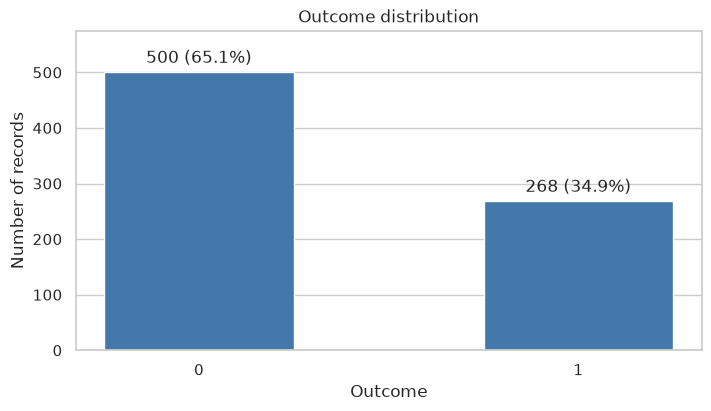

In [19]:
outcome_counts = df_raw[target_column].value_counts(dropna=False).sort_index()
outcome_shares = outcome_counts / record_count
bar_labels = [
    f"{count:,} ({share:.1%})"
    for count, share in zip(outcome_counts, outcome_shares)
]

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
bars = ax.bar(outcome_counts.index.map(str), outcome_counts, width=0.5, color="#4477AA")
ax.set(title="Outcome distribution", xlabel="Outcome", ylabel="Number of records")
ax.grid(axis="x", visible=False)
ax.margins(y=0.15)
ax.bar_label(bars, labels=bar_labels, padding=4)
plt.show()

Dữ liệu nhìn chung không có mismatch về type giữa dữ liệu thực tế và dữ liệu lưu trữ.

# 2. Chất lượng Dataset
Quan sát missingness và outlier.

## 2.1. Missingness
Từ bảng tổng quan ở trên, những giá trị bằng `0` khá "vô lý" ở các biến độc lập dạng numeric liên tục. Chẳng hạn như `insulin`, `skinThickness` thì khó có thể nào mà bằng `0` một cách tuyệt đối như vậy được.

Chính vì vậy, ta nên kiểm tra sơ qua bằng một thống kê đếm đơn giản cho giá trị missing và giá trị `0` trong dataset theo từng biến độc lập.

In [20]:
outcome = df_raw[target_column]
invalid_outcomes = ~outcome.isin([0, 1])
if invalid_outcomes.any():
    raise ValueError(f"{target_column} has {invalid_outcomes.sum():,} missing or invalid labels.")

predictors = df_raw.drop(columns=target_column)
missing_on_load = predictors.isna().sum()
zeros_in_csv = predictors.eq(0).sum()

zero_as_missing_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
measurements = predictors[zero_as_missing_columns]

df_eda = df_raw.copy()
df_eda[zero_as_missing_columns] = measurements.mask(measurements.eq(0))

missing_after_zero_rule = df_eda[predictors.columns].isna().sum()
missingness_overview = pd.DataFrame({
    "Missing on load": missing_on_load,
    "Zeros in CSV": zeros_in_csv,
    "Zeros treated as missing": missing_after_zero_rule - missing_on_load,
    "Total missing": missing_after_zero_rule,
    "Missing (%)": (100 * missing_after_zero_rule / len(df_raw)).round(2),
}).rename_axis("Predictor")
display(missingness_overview)

missing_measurements = df_eda[zero_as_missing_columns].isna()
complete_rows = (~missing_measurements.any(axis=1)).sum()
both_missing = missing_measurements[["Insulin", "SkinThickness"]].all(axis=1).sum()

print(f"Rows with all five measurements recorded: {complete_rows:,} of {len(df_raw):,}")
print(f"Rows missing both Insulin and SkinThickness: {both_missing:,}")


,Missing on load,Zeros in CSV,Zeros treated as missing,Total missing,Missing (%)
Predictor,,,,,
Pregnancies,0,111,0,0,0.00
Glucose,0,5,5,5,0.65
BloodPressure,0,35,35,35,4.56
SkinThickness,0,227,227,227,29.56
Insulin,0,374,374,374,48.70
BMI,0,11,11,11,1.43
DiabetesPedigreeFunction,0,0,0,0,0.00
Age,0,0,0,0,0.00


Rows with all five measurements recorded: 392 of 768
Rows missing both Insulin and SkinThickness: 227


Dựa trên cột `Missing on load`, ta thấy được file raw dataset sau khi được Pandas load không tồn tại các giá trị đại diện cho missing.
Chính vì vậy, với các biến độc lập liên tục như `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, và `BMI`, ta có thể coi giá trị `0` là giá trị không hợp lệ và được dùng để đại diện cho missingness. Tuy nhiên, giá trị của `Pregnancies` vì là giá trị rời rạc thể hiện count, nên giá trị `0` là hoàn toàn hợp lệ.

Ta sẽ chuyển các giá trị `0` của 5 biến này về `NaN` để không làm ảnh hưởng tới việc phân tích ở những phần sau.

## 2.2. Phân tích Outlier

Kết hợp histogram và boxplot để vừa quan sát phân bố, xu hướng trung tâm, độ phân tán, cũng như sự tồn tại của các outlier.

Note: `n` ở đây là tổng quan sát có giá trị khi xét theo từng biến mà hợp lệ (khác `NaN`).

Trước tiên, ta tách riêng ra thành 2 split train/test, và dùng tập train để quan sát tiếp cũng như tiền xử lý dữ liệu.

In [7]:
# Create a stratified train/test split
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(
    df_eda,
    test_size=0.20,
    random_state=42,
    stratify=df_eda[target_column],
)

print(f"Training set: {len(df_train):,} rows | Held-out test set: {len(df_test):,} rows")


Training set: 614 rows | Held-out test set: 154 rows


,Observed,Mean,Median,SD,Q1,Q3,IQR,IQR flags
Predictor,,,,,,,,
Pregnancies,614,3.82,3.00,3.31,1.00,6.00,5.00,2
Glucose,610,121.70,117.00,30.10,99.00,140.75,41.75,0
BloodPressure,591,72.15,72.00,12.51,64.00,80.00,16.00,13
SkinThickness,439,29.06,29.00,10.52,21.00,36.00,15.00,2
Insulin,324,149.08,125.00,107.23,76.00,183.50,107.50,17
BMI,605,32.45,32.40,6.87,27.60,36.60,9.00,6
DiabetesPedigreeFunction,614,0.48,0.38,0.33,0.24,0.64,0.39,19
Age,614,33.37,29.00,11.83,24.00,41.00,17.00,6


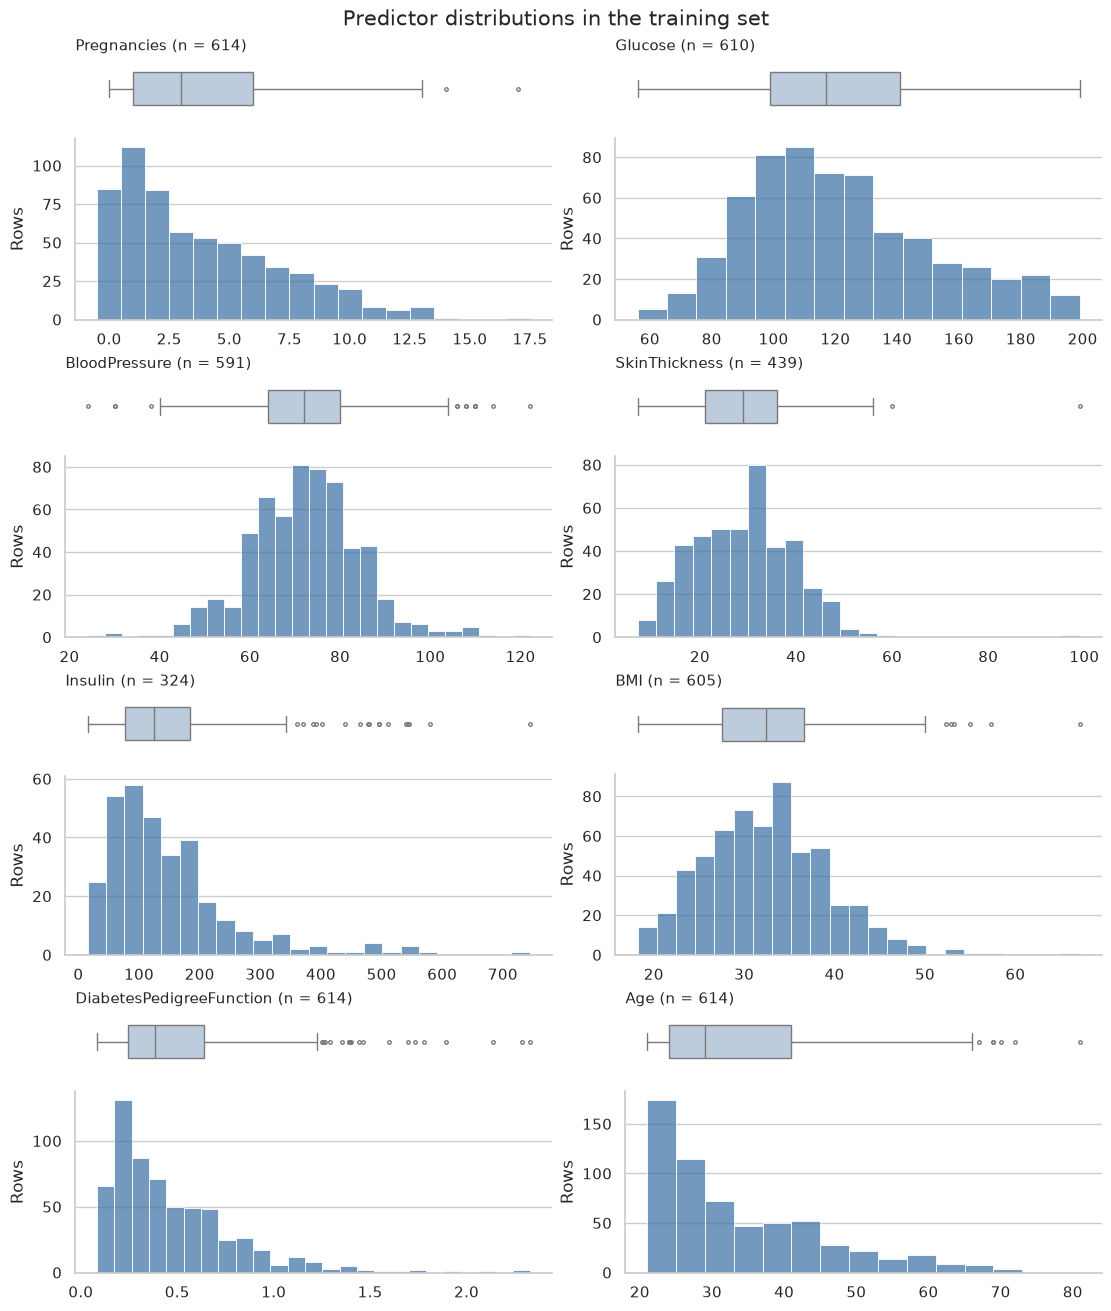

In [8]:
# Inspect observed predictor values in the training set
train_features = df_train.drop(columns=target_column)
summary_columns = {
    "count": "Observed",
    "mean": "Mean",
    "50%": "Median",
    "std": "SD",
    "25%": "Q1",
    "75%": "Q3",
}
distribution_summary = train_features.describe().T[list(summary_columns)].rename(columns=summary_columns)
distribution_summary["Observed"] = distribution_summary["Observed"].astype(int)
distribution_summary["IQR"] = distribution_summary["Q3"] - distribution_summary["Q1"]

# Flag observations outside the boxplot fences for review.
iqr_multiplier = 1.5
lower_fences = distribution_summary["Q1"] - iqr_multiplier * distribution_summary["IQR"]
upper_fences = distribution_summary["Q3"] + iqr_multiplier * distribution_summary["IQR"]
outside_fences = train_features.lt(lower_fences) | train_features.gt(upper_fences)
distribution_summary["IQR flags"] = outside_fences.sum()
display(distribution_summary.round(2).rename_axis("Predictor"))

fig = plt.figure(figsize=(11, 13), layout="constrained")
fig.suptitle("Predictor distributions in the training set", fontsize=15)
grid = fig.add_gridspec((train_features.shape[1] + 1) // 2, 2)
for position, feature in enumerate(train_features.columns):
    row, column = divmod(position, 2)
    panel = grid[row, column].subgridspec(2, 1, height_ratios=(1, 3), hspace=0.03)
    box_ax = fig.add_subplot(panel[0])
    hist_ax = fig.add_subplot(panel[1], sharex=box_ax)
    observed = train_features[feature].dropna()

    sns.boxplot(
        x=observed, whis=iqr_multiplier, color="#B7CCE1", width=0.55,
        fliersize=2.5, ax=box_ax,
    )
    sns.histplot(
        x=observed, bins="auto", discrete=feature == "Pregnancies",
        color="#4477AA", edgecolor="white", linewidth=0.6, ax=hist_ax,
    )

    box_ax.set_title(f"{feature} (n = {len(observed):,})", loc="left", fontsize=11)
    box_ax.set(xlabel="", ylabel="", yticks=[])
    box_ax.tick_params(axis="x", bottom=False, labelbottom=False)
    box_ax.grid(False)
    sns.despine(ax=box_ax, left=True, bottom=True)

    hist_ax.set(xlabel="", ylabel="Rows")
    hist_ax.grid(axis="x", visible=False)
    sns.despine(ax=hist_ax)

plt.show()


# 3. Phân tích hai biến

## 3.1. Predictor vs. `Outcome`

Phân tích dùng tập train. 

Note: Cột `Observed` đếm số giá trị quan sát được theo biến đó mà hợp lệ. Tỷ lệ thiếu (cột `Missing (%)`) thì dùng tổng số dòng của từng lớp để làm mẫu số.


Outcome = 0 (N = 400)                 \
                                      Observed  Median    IQR   
Predictor                                                       
Pregnancies                                400    2.00   4.00   
Glucose                                    398  108.00  30.00   
BloodPressure                              388   70.00  16.00   
SkinThickness                              292   27.00  14.00   
Insulin                                    215  100.00  94.00   
BMI                                        393   30.10   9.20   
DiabetesPedigreeFunction                   400    0.34   0.35   
Age                                        400   27.00  14.00   

                         Outcome = 1 (N = 214)                  
                                      Observed  Median     IQR  
Predictor                                                       
Pregnancies                                214    4.00    6.75  
Glucose                                    212  141.50   49.00  
BloodPressure                              203   76.00   15.00  
SkinThickness                              147   33.00   12.00  
Insulin                                    109  168.00  101.00  
BMI                                        212   34.35    8.05  
DiabetesPedigreeFunction                   214    0.46    0.46  
Age                                        214   36.00   16.75

,Outcome,Predictor,Missing,Rows in class,Missing (%)
0,0,Insulin,185,400,46.25
1,0,SkinThickness,108,400,27.00
2,1,Insulin,105,214,49.07
3,1,SkinThickness,67,214,31.31


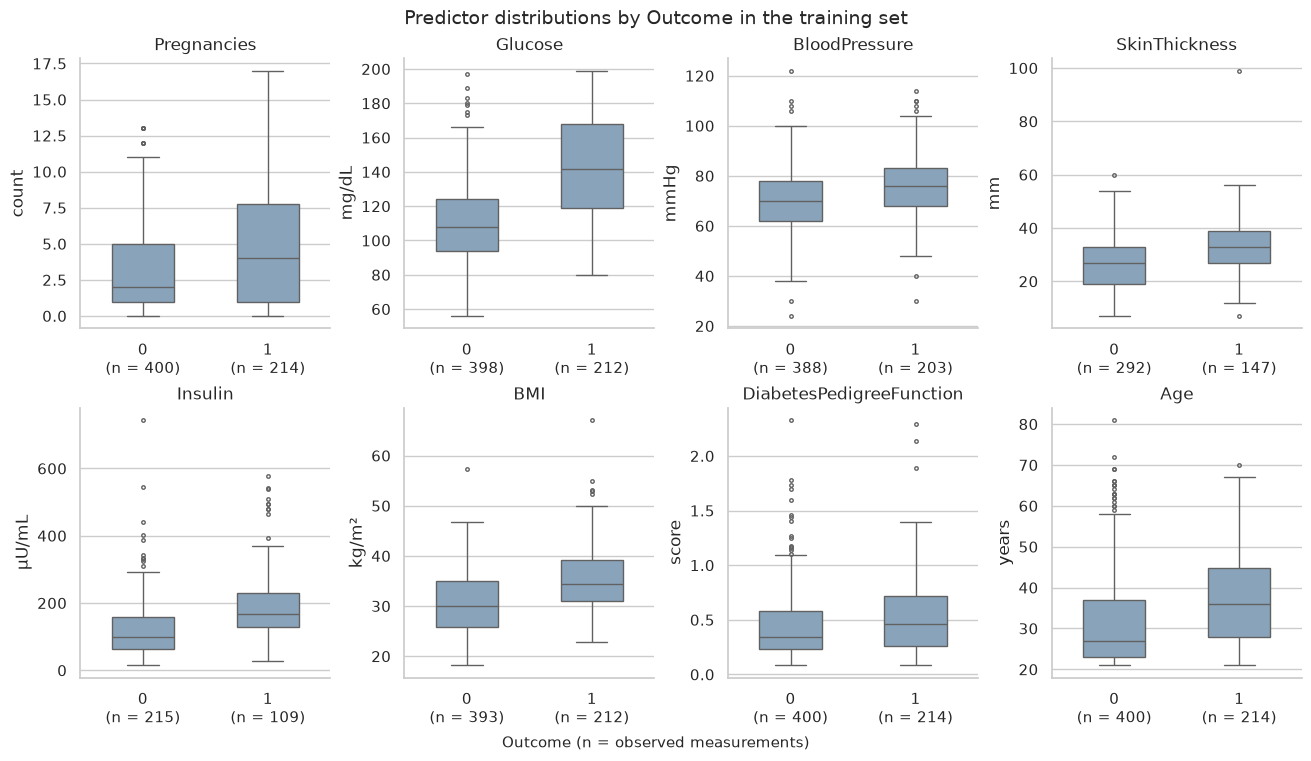

In [ ]:
# Compare predictors by Outcome in the training set
predictor_names = train_features.columns.tolist()
outcome_groups = df_train.groupby(target_column, sort=True)
class_sizes = outcome_groups.size()
class_order = class_sizes.index.tolist()

predictors_by_outcome = outcome_groups[predictor_names]
observed_counts = predictors_by_outcome.count()
medians_by_outcome = predictors_by_outcome.median()
iqr_by_outcome = predictors_by_outcome.quantile(0.75) - predictors_by_outcome.quantile(0.25)

outcome_summary = pd.concat(
    {
        f"Outcome = {label} (N = {class_sizes.loc[label]:,})": pd.DataFrame({
            "Observed": observed_counts.loc[label],
            "Median": medians_by_outcome.loc[label],
            "IQR": iqr_by_outcome.loc[label],
        })
        for label in class_order
    },
    axis=1,
).rename_axis("Predictor")
display(outcome_summary.round(2))

missingness_predictors = ["Insulin", "SkinThickness"]
missing_counts = observed_counts[missingness_predictors].rsub(class_sizes, axis="index")
missingness_by_outcome = (
    missing_counts.rename_axis(columns="Predictor").stack().rename("Missing").reset_index()
)
missingness_by_outcome["Rows in class"] = missingness_by_outcome[target_column].map(class_sizes)
missingness_by_outcome["Missing (%)"] = (
    100 * missingness_by_outcome["Missing"] / missingness_by_outcome["Rows in class"]
).round(2)
display(missingness_by_outcome)

plot_units = {
    "Pregnancies": "count",
    "Glucose": "mg/dL",
    "BloodPressure": "mmHg",
    "SkinThickness": "mm",
    "Insulin": "µU/mL",
    "BMI": "kg/m²",
    "DiabetesPedigreeFunction": "score",
    "Age": "years",
}
fig, axes = plt.subplots(2, 4, figsize=(13, 7.5), layout="constrained")
fig.suptitle("Predictor distributions by Outcome in the training set", fontsize=14)
fig.supxlabel("Outcome (n = observed measurements)", fontsize=11)

for ax, predictor in zip(axes.flat, predictor_names, strict=True):
    sns.boxplot(
        data=df_train, x=target_column, y=predictor, order=class_order,
        whis=iqr_multiplier, width=0.5, color="#81A4C3", fliersize=2.5, ax=ax,
    )
    labels = [
        f"{label}\n(n = {observed_counts.loc[label, predictor]:,})"
        for label in class_order
    ]
    ax.set_xticks(range(len(class_order)), labels=labels)
    ax.set(title=predictor, xlabel="", ylabel=plot_units[predictor])
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)

plt.show()


# 4. Phân tích đa biến

Pair plot thể hiện mối tương quan giữa các biến độc lập trên tập train. Màu và hình điểm biểu thị `Outcome`. Trên đường chéo, histogram được chuẩn hóa riêng theo lớp và `n` là số giá trị có quan sát hợp lệ theo từng biến.

Note: Trong mỗi scatterplot, `n` là số dòng có đủ cả hai phép đo. `DPF` là `DiabetesPedigreeFunction`.


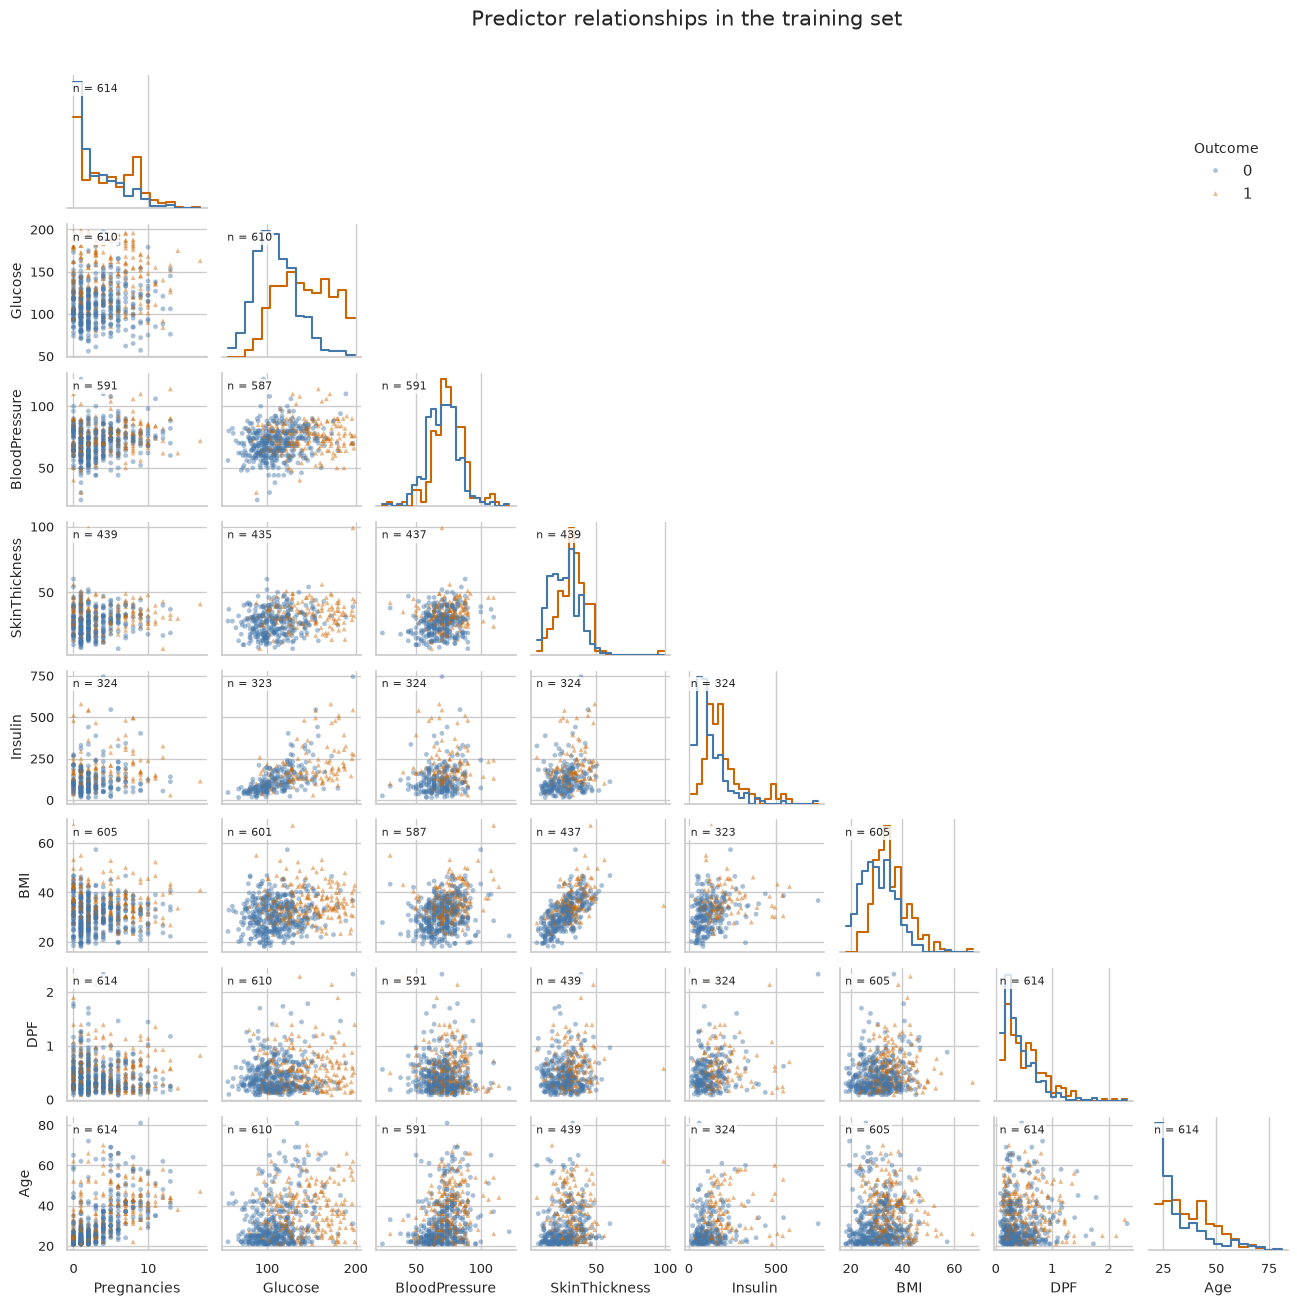

In [11]:
# C7 — View all predictor pairs and their distribution by Outcome
observed = df_train[predictor_names].notna().astype("int64")
pair_counts = observed.T @ observed

with sns.plotting_context("notebook", font_scale=0.85):
    pair_grid = sns.pairplot(
        data=df_train,
        vars=predictor_names,
        hue=target_column,
        hue_order=class_order,
        palette={0: "#4477AA", 1: "#CC6600"},
        markers=["o", "^"],
        corner=True,
        dropna=False,
        diag_kind="hist",
        grid_kws={"diag_sharey": False},
        height=1.65,
        plot_kws={"s": 12, "alpha": 0.45, "linewidth": 0},
        diag_kws={"stat": "density", "common_norm": False, "element": "step", "fill": False},
    )

pair_grid.figure.suptitle("Predictor relationships in the training set", y=0.99, fontsize=15)
pair_grid.figure.subplots_adjust(top=0.94)
sns.move_legend(pair_grid, "upper right", bbox_to_anchor=(0.92, 0.9), frameon=False)

short_labels = {"DiabetesPedigreeFunction": "DPF"}
for row, y_feature in enumerate(predictor_names):
    for column, x_feature in enumerate(predictor_names[:row + 1]):
        ax = pair_grid.diag_axes[row] if row == column else pair_grid.axes[row, column]
        ax.text(
            0.04, 0.94, f"n = {pair_counts.loc[y_feature, x_feature]:,}",
            transform=ax.transAxes, va="top", fontsize=8,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1.2},
        )
    pair_grid.axes[row, 0].set_ylabel(short_labels.get(y_feature, y_feature))

for column, feature in enumerate(predictor_names):
    pair_grid.axes[-1, column].set_xlabel(short_labels.get(feature, feature))

plt.show()


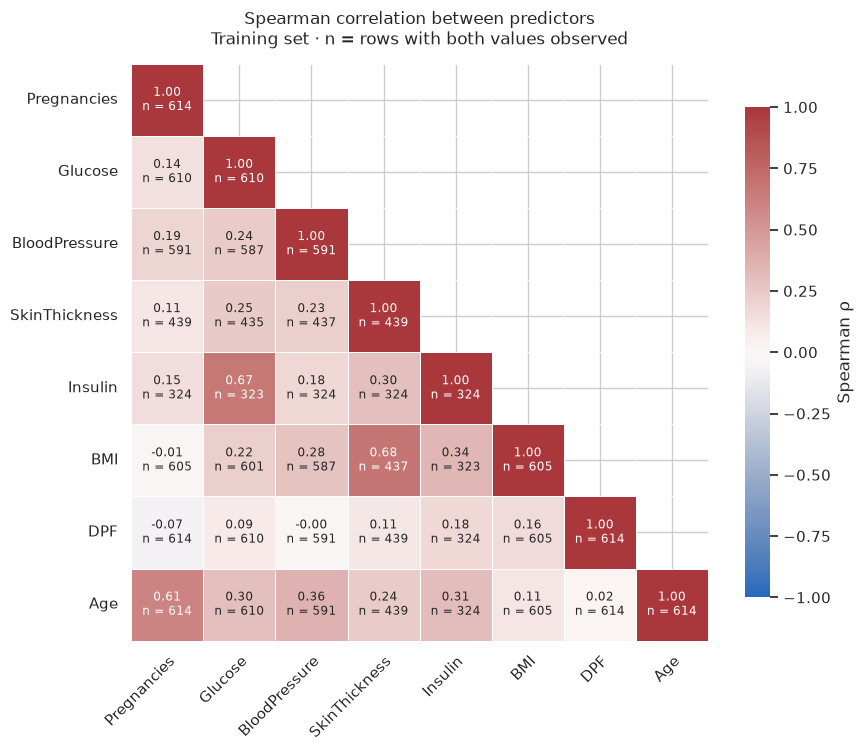

In [12]:
# C8 — Spearman correlations between predictors in the training set
import numpy as np

if "df_train" not in globals():
    raise RuntimeError("Run the notebook through the train/test split first to create df_train.")

heatmap_features = df_train.drop(columns=target_column)
observed_for_heatmap = heatmap_features.notna().astype("int64")
heatmap_pair_counts = observed_for_heatmap.T @ observed_for_heatmap
spearman_matrix = heatmap_features.corr(method="spearman")
upper_triangle = np.triu(np.ones(spearman_matrix.shape, dtype=bool), k=1)
annotations = spearman_matrix.map(lambda rho: f"{rho:.2f}") + "\nn = " + heatmap_pair_counts.astype(str)
axis_labels = ["DPF" if predictor == "DiabetesPedigreeFunction" else predictor for predictor in heatmap_features.columns]

fig, ax = plt.subplots(figsize=(9.0, 7.4), layout="constrained")
sns.heatmap(
    spearman_matrix,
    mask=upper_triangle,
    annot=annotations,
    fmt="",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.7,
    linecolor="white",
    xticklabels=axis_labels,
    yticklabels=axis_labels,
    annot_kws={"fontsize": 8.5},
    cbar_kws={"label": "Spearman ρ", "shrink": 0.85},
    ax=ax,
)
ax.set_title("Spearman correlation between predictors\nTraining set · n = rows with both values observed", pad=14)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax.tick_params(axis="y", labelrotation=0)
plt.show()
